In [1]:
import itertools

import matplotlib.pyplot as plt
import MDAnalysis as mda
import numpy as np
from matplotlib.colors import CenteredNorm
from MDAnalysis.analysis.align import alignto
from tqdm import tqdm

from mg_sampling import PROJECT_DIR
from mg_sampling.density.align import (
    check_alignable,
    reorder_residue_atoms,
    standardize_names,
    unwrap_sequential,
    wrap_around_atomgroup,
)
from mg_sampling.density.forward_density import atomgroup_to_map, voxels_around
from mg_sampling.density.grid import Grid, SparseGrid

/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Alignment and forward map

In [2]:
out_radius = 10
device = 'cuda'
chunk_size = 8192

# Reference structure to align to
ref = mda.Universe(PROJECT_DIR / 'density/9CBU.pdb')
# Reference CryoEM map (for map geometry)
refmap = Grid(PROJECT_DIR / 'density/emd_42499.map', file_format='mrc')

methods = ['replex', 'plain_md']
systems = ['7ez0', '7ez0_noion', '7ez0_nomg']
forcefields = ['mMg_tip3p', 'nMg_tip3p', 'nMg_tip3p_soft']
replicates = range(8)
start = 1500  # after 150 ns equilibration

def run_plain_md(params):
    meth, sys, ff, rep = params

    path = PROJECT_DIR / f'{meth}/{sys}/{ff}/rep{rep:02d}'

    if not path.exists():
        print("Skip:", path)
        return

    outpath = PROJECT_DIR / f'density/{meth}_{sys}_{ff}'
    outpath.mkdir(exist_ok=True, parents=True)

    u = mda.Universe(
        path / 'input.gro',
        path /'run.xtc',
    )

    standardize_names(u)

    mob_align = reorder_residue_atoms(u.select_atoms('not type H and nucleic'))
    mob_align_light = mob_align.select_atoms('name P')[::5]  # For efficiently wrapping solvent around
    ref_align = reorder_residue_atoms(ref.select_atoms('not type H and nucleic and not (resid 22 and name P OP1 OP2)'))

    vox_indices = voxels_around(ref_align, 6, refmap.grid_params)

    check_alignable(mob_align, ref_align)

    mob_out = u.select_atoms("not type H")
    mob_out = mob_out.select_atoms(f"group mob_align or around {out_radius} group mob_align", mob_align=mob_align, updating=True)

    tot_map = 0
    for ts in tqdm(u.trajectory[start:]):
        unwrap_sequential(mob_align)
        wrap_around_atomgroup(mob_out, mob_align_light)
        alignto(mob_align, ref_align, subselection=mob_out)
        map_ = atomgroup_to_map(
            mob_out,
            shape=refmap.shape,
            delta=refmap.delta,
            origin=refmap.origin,
            vox_indices=vox_indices,
            device=device,
            chunk_size=chunk_size,
        )
        tot_map += map_
    tot_map /= len(u.trajectory[start:])
    tot_map.save(outpath / f'global_rep{i:02d}.pkl')

/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:479: UserWarning: 1 A^3 CRYST1 record, this is usually a placeholder. Unit cell dimensions will be set to None.
  warnings.warn(


In [5]:
from dask import compute, delayed

tasks = [delayed(run_plain_md)(params) for params in itertools.product(methods, systems, forcefields, replicates)]

In [ ]:
compute(*tasks, scheduler='processes', num_workers=6)

/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/site-packages/cloudpickle/cloudpickle.py:1313: UserWarning: Reader has no dt information, set to 1.0 ps
  return super().dump(obj)


Skip: /net/sbp/sbpstore2/olanguin/mg_sampling/replex/7ez0_nomg/mMg_tip3p/rep02
Skip: /net/sbp/sbpstore2/olanguin/mg_sampling/plain_md/7ez0_noion/mMg_tip3p/rep06
Skip: /net/sbp/sbpstore2/olanguin/mg_sampling/replex/7ez0_noion/mMg_tip3p/rep02
Skip: /net/sbp/sbpstore2/olanguin/mg_sampling/plain_md/7ez0_noion/nMg_tip3p_soft/rep07
Skip: /net/sbp/sbpstore2/olanguin/mg_sampling/replex/7ez0_nomg/mMg_tip3p/rep05
Skip: /net/sbp/sbpstore2/olanguin/mg_sampling/replex/7ez0_nomg/mMg_tip3p/rep00
Skip: /net/sbp/sbpstore2/olanguin/mg_sampling/replex/7ez0_nomg/nMg_tip3p/rep00
Skip: /net/sbp/sbpstore2/olanguin/mg_sampling/replex/7ez0_nomg/nMg_tip3p/rep02
Skip: /net/sbp/sbpstore2/olanguin/mg_sampling/replex/7ez0_noion/mMg_tip3p/rep03
Skip: /net/sbp/sbpstore2/olanguin/mg_sampling/replex/7ez0_nomg/nMg_tip3p_soft/rep07
Skip: /net/sbp/sbpstore2/olanguin/mg_sampling/plain_md/7ez0_noion/mMg_tip3p/rep05
Skip: /net/sbp/sbpstore2/olanguin/mg_sampling/replex/7ez0/nMg_tip3p_soft/rep05
Skip: /net/sbp/sbpstore2/olangu

  9%|▉         | 336/3798 [06:20<1:05:16,  1.13s/it]


Skip: /net/sbp/sbpstore2/olanguin/mg_sampling/replex/7ez0/mMg_tip3p/rep05
Skip: /net/sbp/sbpstore2/olanguin/mg_sampling/replex/7ez0_noion/nMg_tip3p_soft/rep04
Skip: /net/sbp/sbpstore2/olanguin/mg_sampling/replex/7ez0_noion/nMg_tip3p/rep05
Skip: /net/sbp/sbpstore2/olanguin/mg_sampling/plain_md/7ez0_noion/nMg_tip3p_soft/rep06


  0%|          | 4/3763 [00:04<1:07:17,  1.07s/it]

## Compute CC and estimate error

In [ ]:
from functools import reduce


2

In [ ]:
maps = []
for i in replicas:
    path = PROJECT_DIR / f'density/plain_md_7ez0_mMg_tip3p_replicate0/rep{i:02d}'
    filenames = list(path.glob("*.pkl"))
    maps.append(
        sum(map(SparseGrid.load, tqdm(filenames)))
    )


100%|██████████| 11/11 [00:00<00:00, 160.01it/s]












100%|██████████| 11/11 [00:01<00:00,  6.90it/s]








100%|██████████| 11/11 [00:01<00:00,  9.78it/s]









100%|██████████| 11/11 [00:01<00:00,  9.56it/s]












100%|██████████| 11/11 [00:01<00:00,  7.91it/s]












100%|██████████| 11/11 [00:01<00:00,  6.48it/s]










100%|██████████| 11/11 [00:01<00:00,  9.46it/s]









100%|██████████| 11/11 [00:01<00:00,  9.59it/s]


In [38]:
maps

In [21]:
tot_map = sum(maps) / len(maps)

In [22]:
def plot_map_slice(grid: Grid, plane='xy', depth=0.5, depth_mode='fraction', norm=None, cmap='RdBu_r', ax=None, **kwargs):
    if ax is None:
        ax = plt.gca()
    
    if norm is None:
        norm = CenteredNorm()

    x_axis, y_axis = ['xyz'.index(dim) for dim in plane]
    depth_axis = ({0, 1, 2} - set((x_axis, y_axis))).pop()
    midpoints = grid.midpoints[depth_axis]
    x_edges, y_edges = grid.edges[x_axis], grid.edges[y_axis]
    extent = [*x_edges[[0, -1]], *y_edges[[0, - 1]]]
    z_edges = grid.edges[depth_axis]

    if depth_mode == 'fraction':
        k = int(depth * len(midpoints))
    elif depth_mode == 'index':
        k = int(depth)
    elif depth_mode == 'coord':
        k = int(np.searchsorted(midpoints, depth, side="left"))
    
    s = tuple(slice(None) if d in (x_axis, y_axis) else k for d in (0, 1, 2))
    im = ax.imshow(grid.grid[s].T, origin='lower', norm=norm, cmap=cmap, extent=extent, **kwargs)

    ax.set_xlabel('xyz'[x_axis])
    ax.set_ylabel('xyz'[y_axis])

    return ax

<Axes: xlabel='x', ylabel='y'>

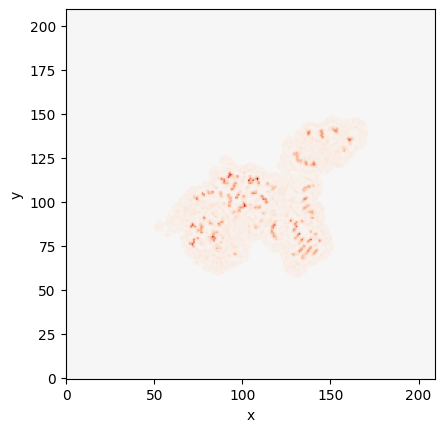

In [39]:
plot_map_slice(sum(maps).to_dense())